# Notebook 01 — El Problema de Negocio y Contexto Industrial

## Sensores Virtuales y Analizadores en Línea

En una refinería, el **punto de inflamación del keroseno (*flash point*)** determina la seguridad y comerciabilidad del combustible:
- **Límite inferior:** `38.0 °C` (riesgo de explosión / rechazo inmediato)
- **Límite superior:** `60.0 °C` (arrastre de fracciones pesadas / pérdida de rendimiento)
- **Punto objetivo operativo:** `48.0 °C`

**La brecha de medición:** el laboratorio entrega un análisis cada **8 horas** (una vez por turno). Durante esas 8 horas el operador gobierna la torre sin visibilidad directa de calidad.
El **sensor virtual** estima el *flash point* cada minuto a partir de las señales continuas del DCS/SCADA (nivel ISA-95 L2/L3 vía OPC UA).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]

DATA_URL = "https://d29ikw7e1z6k4e.cloudfront.net/curso_sensor/curso_sensor_raw_data.csv"
df = pd.read_csv(DATA_URL)
df["date_dt"] = pd.to_datetime(df["date"])

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]-1} columnas")
print(f"Cobertura  : {df['date_dt'].min()} -> {df['date_dt'].max()}")
df.head()

Dimensiones: 1098 filas x 17 columnas
Cobertura  : 2025-01-01 00:00:00 -> 2025-12-31 16:00:00


,date,feed_flow_rate_m3h,feed_temperature_C,column_top_temp_C,column_top_pressure_kPag,column_delta_p_kPa,tray_15_temp_C,kerosene_draw_temp_C,column_bottom_temp_C,reflux_flow_m3h,reflux_ratio,kerosene_product_flow_m3h,stripping_steam_flow_kgh,condenser_outlet_temp_C,ambient_temp_C,crude_api_gravity,flash_point_lab_C,date_dt
0,2025-01-01 00:00:00,965.1,366.1,108.6,111.53,19.49,201.1,182.0,356.1,291.5,2.097,114.8,2126.8,38.0,-4.6,33.93,48.7,2025-01-01 00:00:00
1,2025-01-01 08:00:00,946.5,361.8,107.4,109.49,19.15,202.5,180.4,351.2,286.6,2.033,110.0,2219.3,41.2,-0.2,34.05,49.7,2025-01-01 08:00:00
2,2025-01-01 16:00:00,947.8,366.3,109.2,109.73,20.22,204.3,183.2,354.7,282.7,2.093,112.0,2220.8,41.1,-1.1,33.67,51.7,2025-01-01 16:00:00
3,2025-01-02 00:00:00,964.1,363.6,107.8,107.90,20.75,202.9,183.0,354.2,291.1,1.985,106.7,2282.0,37.5,-3.9,33.84,55.5,2025-01-02 00:00:00
4,2025-01-02 08:00:00,968.5,362.4,109.0,110.01,19.62,199.3,179.9,352.1,300.7,2.106,116.2,2372.2,39.1,-1.4,33.93,49.8,2025-01-02 08:00:00


### Diccionario Completo de Variables (17 columnas reales del DCS y Laboratorio)

| Columna | Tipo | Descripción | Unidad |
|---|---|---|---|
| `date` | Marca de tiempo | Sello temporal del turno (cada 8 horas) | YYYY-MM-DD HH:MM:SS |
| `feed_flow_rate_m3h` | Entrada DCS | Caudal de carga a la columna atmosférica | m³/h |
| `feed_temperature_C` | Entrada DCS | Temperatura de precalentamiento de alimentación | °C |
| `column_top_temp_C` | Entrada DCS | Temperatura en el tope de la columna | °C |
| `column_top_pressure_kPag` | Entrada DCS | Presión manométrica en el tope | kPag |
| `column_delta_p_kPa` | Entrada DCS | Caída de presión hidráulica a través de platos | kPa |
| `tray_15_temp_C` | Entrada DCS | Temperatura en el plato 15 (zona de fraccionamiento) | °C |
| `kerosene_draw_temp_C` | Entrada DCS | Temperatura de extracción lateral de keroseno | °C |
| `column_bottom_temp_C` | Entrada DCS | Temperatura en el fondo de la torre | °C |
| `reflux_flow_m3h` | Entrada DCS | Caudal de reflujo superior | m³/h |
| `reflux_ratio` | Entrada DCS | Relación de reflujo interna | adim. |
| `kerosene_product_flow_m3h` | Entrada DCS | Caudal neto de producto keroseno | m³/h |
| `stripping_steam_flow_kgh` | Entrada DCS | Vapor de despojamiento al *stripper* | kg/h |
| `condenser_outlet_temp_C` | Entrada DCS | Temperatura de salida del condensador | °C |
| `ambient_temp_C` | Entrada DCS | Temperatura ambiente (ciclo estacional) | °C |
| `crude_api_gravity` | Entrada Lab/Online | Gravedad API de la dieta de crudo | °API |
| `flash_point_lab_C` | **Objetivo** | Punto de inflamación medido en laboratorio | °C |

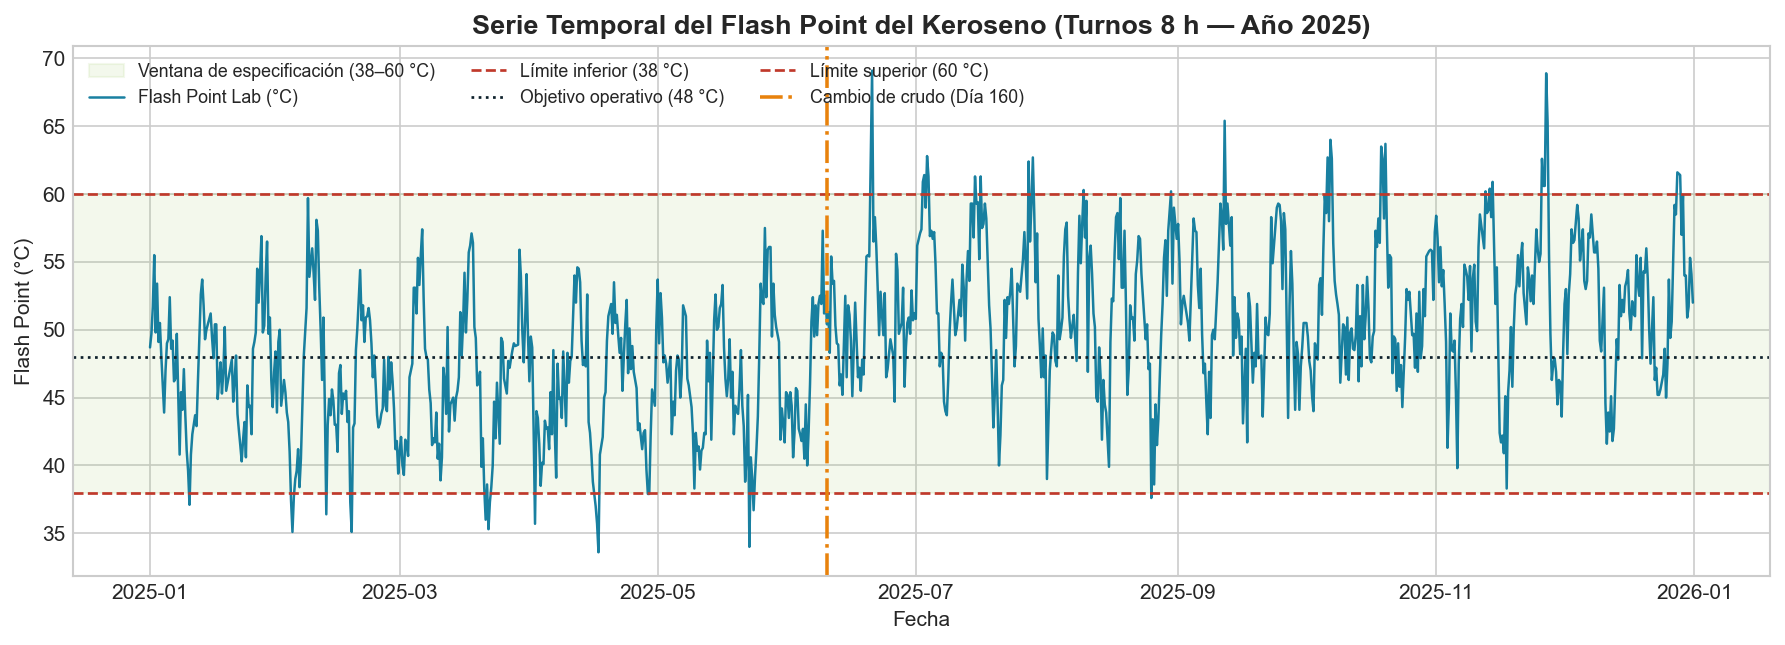

Estadísticas de Flash Point (lecturas físicamente válidas):
  Registros válidos : 1034 | Nulos: 62 | Errores lab (<0 o >100): 2
  Mínimo / Máximo   : 33.6 °C / 69.1 °C
  Media / Desv. std : 49.43 °C / 5.70 °C
  Fuera espec <38 °C: 20 turnos | >60 °C: 28 turnos


In [2]:
# Visualizar la variable objetivo y el cambio de crudo
valid_fp = df[(df["flash_point_lab_C"] > 0) & (df["flash_point_lab_C"] < 100)].copy()

fig, ax = plt.subplots(figsize=(12, 4.4), dpi=150)
ax.axhspan(38, 60, color="#8EC14B", alpha=0.10, label="Ventana de especificación (38–60 °C)")
ax.plot(valid_fp["date_dt"], valid_fp["flash_point_lab_C"], color=COLORS[0], linewidth=1.2, alpha=0.9, label="Flash Point Lab (°C)")
ax.axhline(38, color=COLORS[3], linestyle="--", linewidth=1.3, label="Límite inferior (38 °C)")
ax.axhline(48, color=COLORS[4], linestyle=":", linewidth=1.3, label="Objetivo operativo (48 °C)")
ax.axhline(60, color=COLORS[3], linestyle="--", linewidth=1.3, label="Límite superior (60 °C)")
ax.axvline(pd.Timestamp("2025-06-10"), color=COLORS[2], linestyle="-.", linewidth=1.7, label="Cambio de crudo (Día 160)")

ax.set_title("Serie Temporal del Flash Point del Keroseno (Turnos 8 h — Año 2025)", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Flash Point (°C)")
ax.legend(loc="upper left", fontsize=8.5, ncol=3)
plt.tight_layout()
plt.show()

print("Estadísticas de Flash Point (lecturas físicamente válidas):")
print(f"  Registros válidos : {len(valid_fp)} | Nulos: {df['flash_point_lab_C'].isna().sum()} | Errores lab (<0 o >100): {((df['flash_point_lab_C'] <= 0) | (df['flash_point_lab_C'] >= 100)).sum()}")
print(f"  Mínimo / Máximo   : {valid_fp['flash_point_lab_C'].min():.1f} °C / {valid_fp['flash_point_lab_C'].max():.1f} °C")
print(f"  Media / Desv. std : {valid_fp['flash_point_lab_C'].mean():.2f} °C / {valid_fp['flash_point_lab_C'].std():.2f} °C")
print(f"  Fuera espec <38 °C: {(valid_fp['flash_point_lab_C'] < 38).sum()} turnos | >60 °C: {(valid_fp['flash_point_lab_C'] > 60).sum()} turnos")

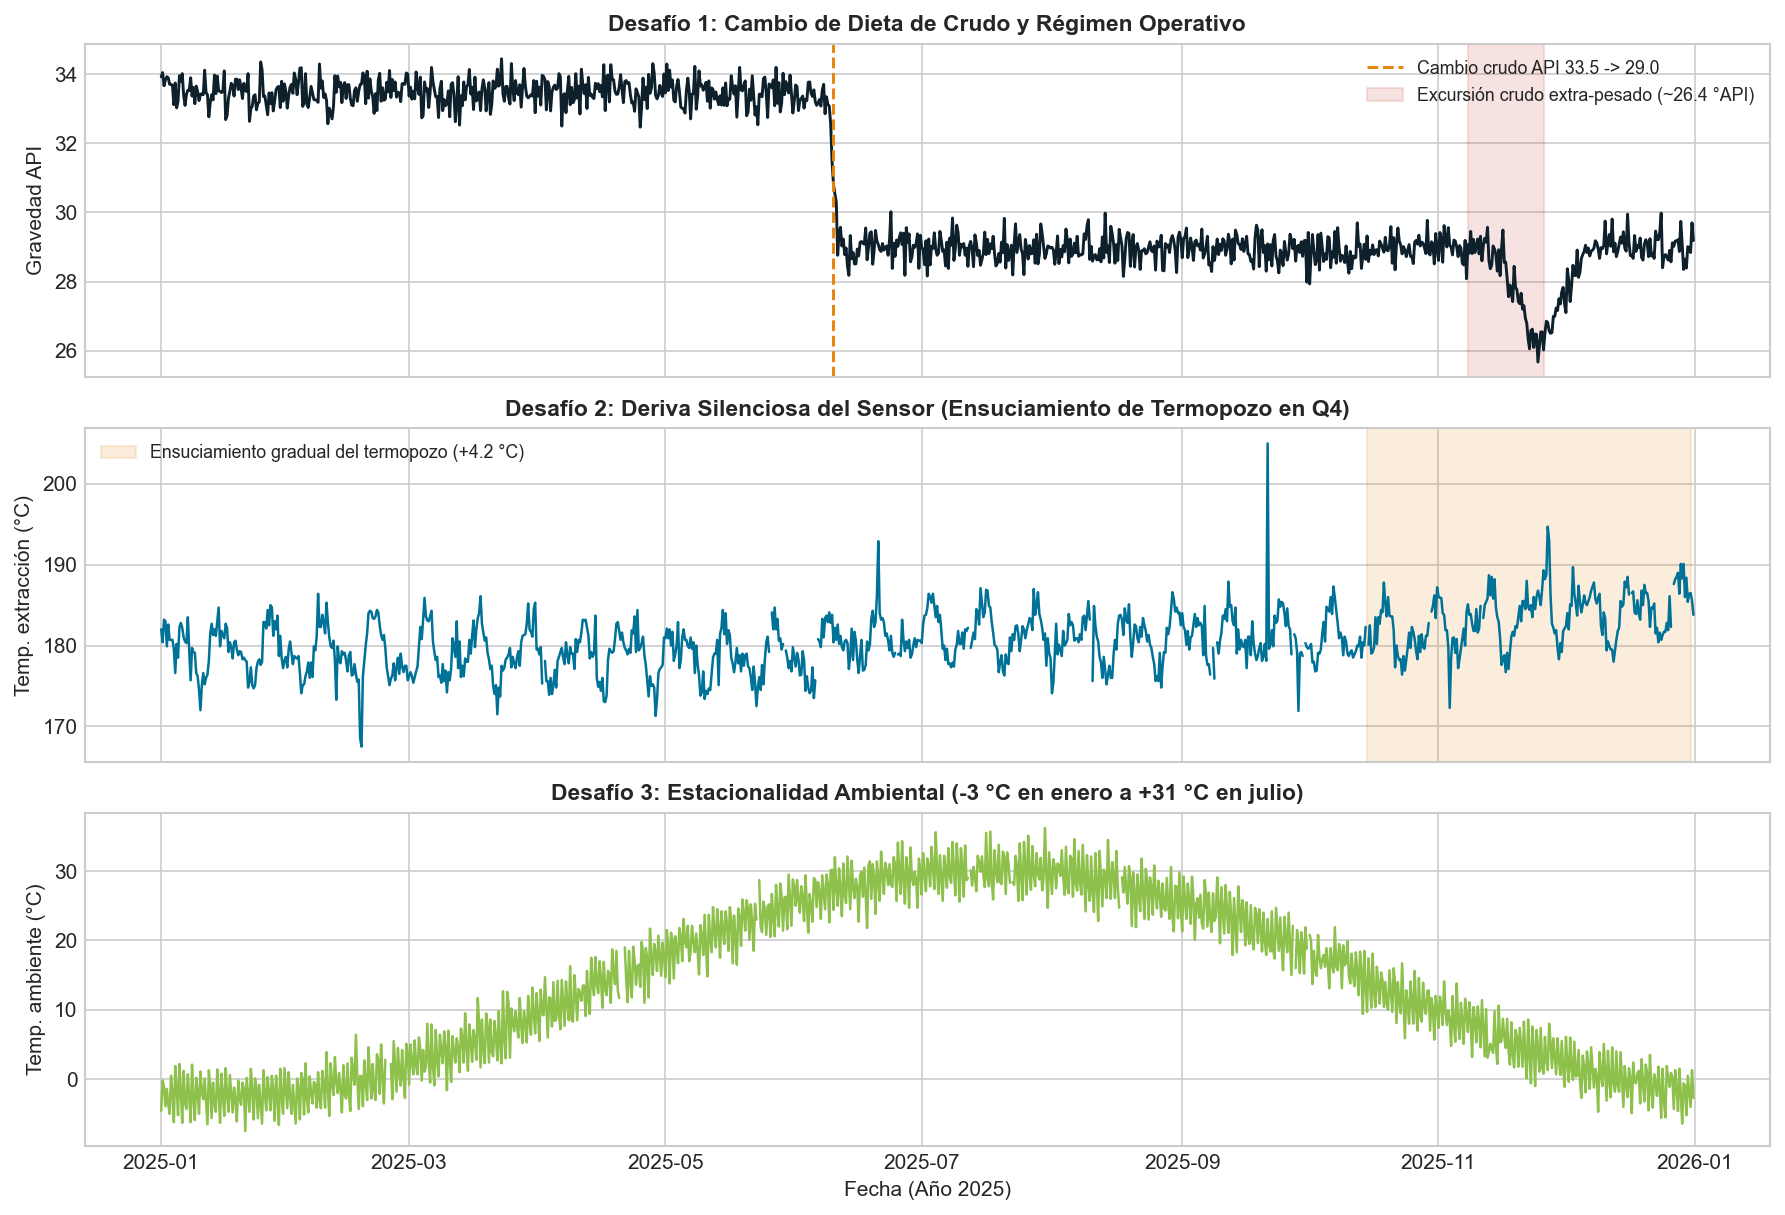

In [3]:
# Visualizar los tres desafíos industriales reales del dataset
fig, axes = plt.subplots(3, 1, figsize=(12, 8.2), dpi=150, sharex=True)

# 1. Cambio de crudo y excursión en noviembre
axes[0].plot(df["date_dt"], df["crude_api_gravity"], color=COLORS[4], linewidth=1.4)
axes[0].axvline(pd.Timestamp("2025-06-10"), color=COLORS[2], linestyle="--", linewidth=1.4, label="Cambio crudo API 33.5 -> 29.0")
axes[0].axvspan(pd.Timestamp("2025-11-08"), pd.Timestamp("2025-11-26"), color=COLORS[3], alpha=0.14, label="Excursión crudo extra-pesado (~26.4 °API)")
axes[0].set_title("Desafío 1: Cambio de Dieta de Crudo y Régimen Operativo", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Gravedad API")
axes[0].legend(loc="upper right", fontsize=8.5)

# 2. Deriva del termopozo en Q4
kero_clean_plot = df["kerosene_draw_temp_C"].clip(165, 205)
axes[1].plot(df["date_dt"], kero_clean_plot, color=COLORS[0], linewidth=1.2)
axes[1].axvspan(pd.Timestamp("2025-10-15"), pd.Timestamp("2025-12-31"), color=COLORS[2], alpha=0.14, label="Ensuciamiento gradual del termopozo (+4.2 °C)")
axes[1].set_title("Desafío 2: Deriva Silenciosa del Sensor (Ensuciamiento de Termopozo en Q4)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Temp. extracción (°C)")
axes[1].legend(loc="upper left", fontsize=8.5)

# 3. Estacionalidad térmica anual
axes[2].plot(df["date_dt"], df["ambient_temp_C"], color=COLORS[1], linewidth=1.2)
axes[2].set_title("Desafío 3: Estacionalidad Ambiental (-3 °C en enero a +31 °C en julio)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Temp. ambiente (°C)")
axes[2].set_xlabel("Fecha (Año 2025)")

plt.tight_layout()
plt.show()

In [4]:
# Cuantificación económica: Quality Giveaway y retorno de inversión (ROI)
capacidad_bpd = 50_000          # barriles totales de crudo por día
fraccion_kero = 0.14            # ~14% rendimiento a keroseno (~7,000 bpd)
bpd_kero = capacidad_bpd * fraccion_kero

# Sin sensor virtual, el operador mantiene un colchón excesivo (~50 C vs 44 C) por miedo al límite 38 C
giveaway_usd_bbl = 0.75         # margen conservador de calidad cedida (rango industria: 0.5 - 2.0 USD/bbl)
ahorro_giveaway_anual = bpd_kero * 350 * giveaway_usd_bbl
costo_analizador_fisico = 250_000
costo_sensor_virtual = 35_000

print("=== Caso de Negocio: Sensor Virtual vs Analizador Físico ===")
print(f"  Producción de keroseno unidad tipo : {bpd_kero:,.0f} bpd")
print(f"  Ahorro anual reduciendo giveaway   : USD {ahorro_giveaway_anual:,.0f} / año (@ ${giveaway_usd_bbl:.2f}/bbl)")
print(f"  CAPEX Analizador físico en línea   : USD {costo_analizador_fisico:,.0f} (plazo 18-36 meses)")
print(f"  CAPEX Sensor virtual ML            : USD {costo_sensor_virtual:,.0f} (plazo 60-90 días)")
print(f"  Payback estimado del sensor virtual: {costo_sensor_virtual / ahorro_giveaway_anual * 12:.1f} meses")

=== Caso de Negocio: Sensor Virtual vs Analizador Físico ===
  Producción de keroseno unidad tipo : 7,000 bpd
  Ahorro anual reduciendo giveaway   : USD 1,837,500 / año (@ $0.75/bbl)
  CAPEX Analizador físico en línea   : USD 250,000 (plazo 18-36 meses)
  CAPEX Sensor virtual ML            : USD 35,000 (plazo 60-90 días)
  Payback estimado del sensor virtual: 0.2 meses


### Checkpoint: Lo que debes ver

- Gráfica del *flash point* mostrando la banda de especificación `38–60 °C` y el cambio de crudo en el Día 160 (`2025-06-10`)
- Evidencia visual de los 3 fenómenos reales: cambio de crudo + bolsillo extra-pesado en noviembre, deriva de `+4.2 °C` en `kerosene_draw_temp_C` en Q4, y estacionalidad ambiental anual
- Caso económico cuantificado demostrando por qué reducir el *quality giveaway* paga el proyecto en pocos meses